# EcoSort: AI-Enabled Waste Management Assistant

### Project Overview

An AI-enabled waste management assistant that combines computer vision, natural language processing, and Retrieval-Augmented Generation (RAG) to identify waste materials and provide recycling and disposal guidance

### Part 1: Dataset Exploration and Preparation

In [1]:
! pip install tensorflow

In [1]:
# Import necessary libraries
import os
import random
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import json
import re
from pathlib import Path
from PIL import Image
from collections import Counter

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

Dataset location: c:\Users\kevin\OneDrive\Documents\MS_DS_Projects\Projects\ecosort-waste-management\data\realwaste-main\RealWaste

Number of waste categories: 9
Waste categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']

Total images found: 4752


,Category,Image Count
0,Cardboard,461
1,Food Organics,411
2,Glass,420
3,Metal,790
4,Miscellaneous Trash,495
5,Paper,500
6,Plastic,921
7,Textile Trash,318
8,Vegetation,436


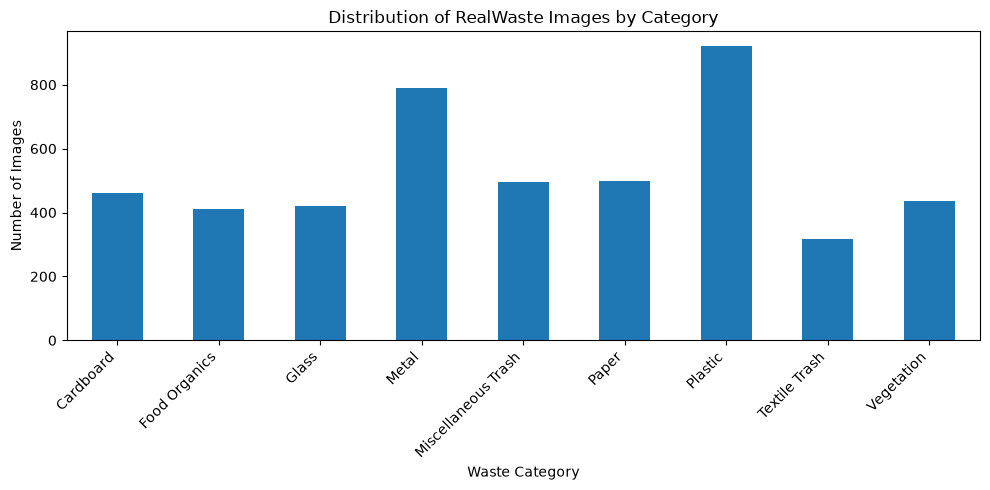


Readable images: 4752
Unreadable or corrupted images: 0

Image resolution statistics:


,width,height
count,4752.0,4752.0
mean,524.0,524.0
std,0.0,0.0
min,524.0,524.0
25%,524.0,524.0
50%,524.0,524.0
75%,524.0,524.0
max,524.0,524.0



Image formats:
format
JPEG    4752
Name: count, dtype: int64

Images by category successfully inspected:


category
Plastic                921
Metal                  790
Paper                  500
Miscellaneous Trash    495
Cardboard              461
Vegetation             436
Glass                  420
Food Organics          411
Textile Trash          318
Name: count, dtype: int64

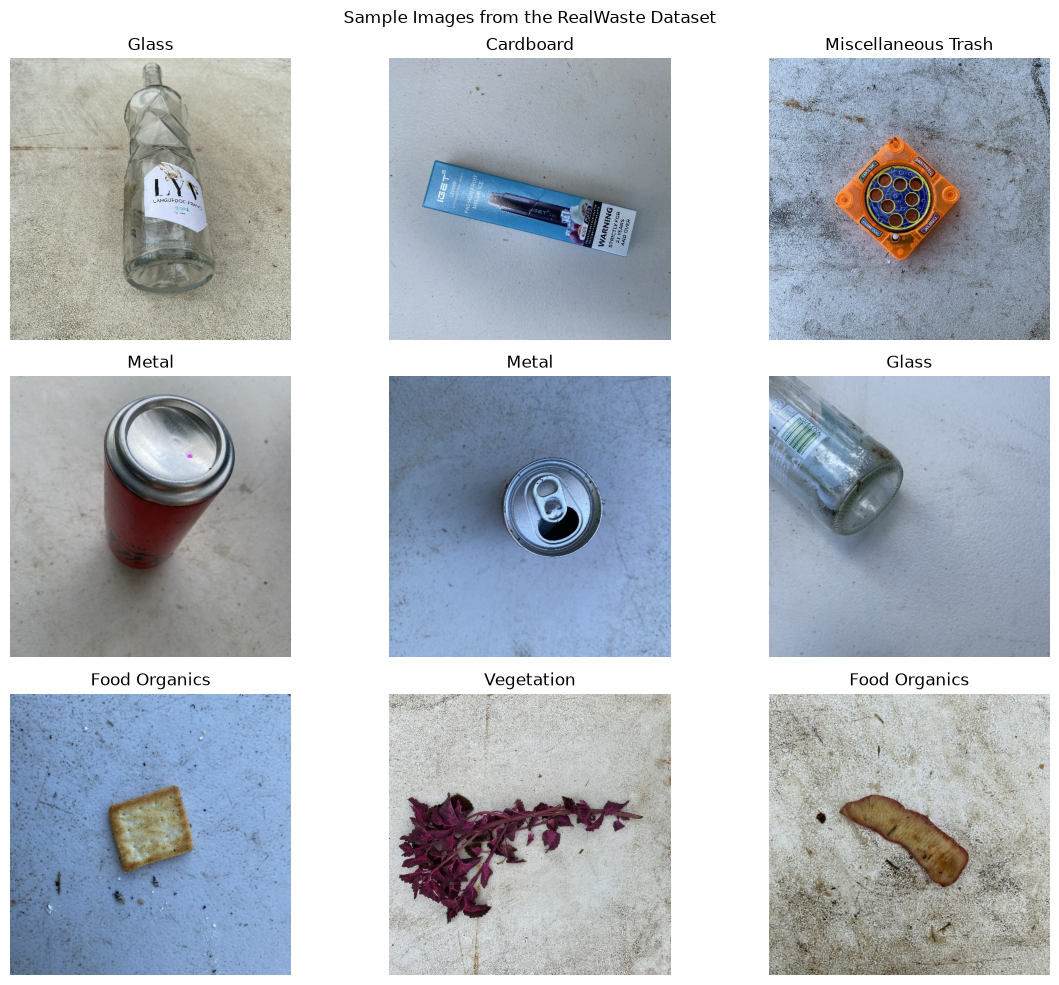

In [2]:
# 1. Locate the RealWaste dataset
PROJECT_DIR = Path.cwd()

possible_paths = [
    PROJECT_DIR / "realwaste-main" / "RealWaste",
    PROJECT_DIR / "RealWaste",
    PROJECT_DIR / "realwaste" / "RealWaste",
]

DATASET_DIR = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

# Search subfolders if the dataset is not in the expected locations
if DATASET_DIR is None:
    for path in PROJECT_DIR.rglob("RealWaste"):
        if path.is_dir() and any(item.is_dir() for item in path.iterdir()):
            DATASET_DIR = path
            break

if DATASET_DIR is None:
    raise FileNotFoundError(
        "RealWaste dataset folder not found. "
        "Update possible_paths to point to your RealWaste directory."
    )

print("Dataset location:", DATASET_DIR)

# 2. Explore the dataset structure
categories = sorted(
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
)

print("\nNumber of waste categories:", len(categories))
print("Waste categories:", categories)

# 3. Count images in each category
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = []
category_counts = {}

for category in categories:
    category_dir = DATASET_DIR / category

    files = [
        path for path in category_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]

    category_counts[category] = len(files)
    image_paths.extend((path, category) for path in files)

category_df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Image Count"]
)

print("\nTotal images found:", len(image_paths))
display(category_df)

# 4. Visualize the distribution of waste categories
if not category_df.empty:
    category_df.plot(
        x="Category",
        y="Image Count",
        kind="bar",
        legend=False,
        figsize=(10, 5)
    )

    plt.title("Distribution of RealWaste Images by Category")
    plt.xlabel("Waste Category")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# 5. Inspect image characteristics
image_info = []
corrupted_images = []

for path, category in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen the image after verify() before reading its properties
        with Image.open(path) as img:
            image_info.append({
                "category": category,
                "width": img.width,
                "height": img.height,
                "format": img.format
            })

    except Exception as error:
        corrupted_images.append(str(path))

# Convert the collected information into DataFrames
image_info = pd.DataFrame(
    image_info,
    columns=["category", "width", "height", "format"]
)

print("\nReadable images:", len(image_info))
print("Unreadable or corrupted images:", len(corrupted_images))

if not image_info.empty:
    print("\nImage resolution statistics:")
    display(image_info[["width", "height"]].describe())

    print("\nImage formats:")
    print(image_info["format"].value_counts())

    print("\nImages by category successfully inspected:")
    display(image_info["category"].value_counts())
else:
    print(
        "\nNo readable images were recorded. "
        "Check the dataset location and image files."
    )

# 6. Display sample images to inspect quality and backgrounds
if image_paths:
    random.seed(42)
    samples = random.sample(image_paths, min(9, len(image_paths)))

    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    axes = axes.flatten()

    for ax, (path, category) in zip(axes, samples):
        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(category)
        except Exception:
            ax.set_title(f"{category}\nImage could not be opened")

        ax.axis("off")

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.suptitle("Sample Images from the RealWaste Dataset")
    plt.tight_layout()
    plt.show()
else:
    print("No image paths available for visual inspection.")